In [1]:
import numpy as np
import cv2 as cv
from multiprocessing.pool import ThreadPool as Pool
from multiprocessing import cpu_count
from typing import Tuple, List, Union
import numba

from PIL import Image

In [2]:
def calculate_gradients(normals: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    normals = normals.astype(np.float64)
    # print(normals[..., 0])
    horizontal_angle_map = np.arccos(np.clip(normals[..., 0], -1, 1))
    left_gradients = np.sign(horizontal_angle_map - np.pi / 2) * (
        1 - np.sin(horizontal_angle_map)
    )

    vertical_angle_map = np.arccos(np.clip(normals[..., 1], -1, 1))
    top_gradients = -np.sign(vertical_angle_map - np.pi / 2) * (
        1 - np.sin(vertical_angle_map)
    )

    return left_gradients, top_gradients

In [8]:
from matplotlib.colors import TwoSlopeNorm
import matplotlib.pyplot as plt
normal_map = np.array(Image.open("normal_mapping_a.png"))

# height_map = Image.fromarray(
#     estimate_height_map(np.array(normal_map, dtype=np.float64))
# )
# height_map.save("Height_map.png")

normals = ((normal_map[:, :, :3] / 255) - 0.5) * 2
# left_gradients, top_gradients = calculate_gradients(normal_map)
# left_gradients


dx = np.gradient(normals, axis=1)
dy = np.gradient(normals, axis=0)

dx

array([[[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]],

       ...,

       [[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        ...,
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]]])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


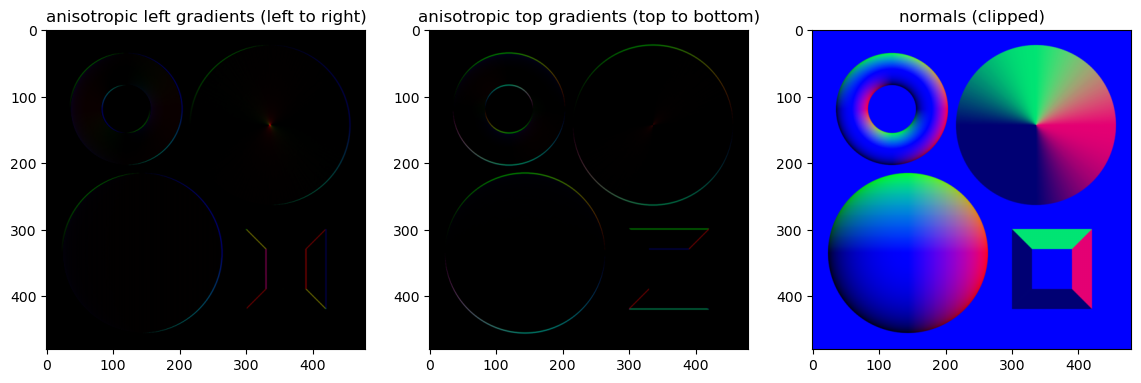

In [9]:

figsize = (14, 14)
figure, axes = plt.subplots(1, 3, figsize=figsize)
axes[0].set_title("anisotropic left gradients (left to right)")
_ = axes[0].imshow(dx, cmap="RdBu", norm=TwoSlopeNorm(0))
axes[1].set_title("anisotropic top gradients (top to bottom)")
_ = axes[1].imshow(dy, cmap="RdBu", norm=TwoSlopeNorm(0))
axes[2].set_title("normals (clipped)")
_ = axes[2].imshow(np.clip(normals, 0, 255))

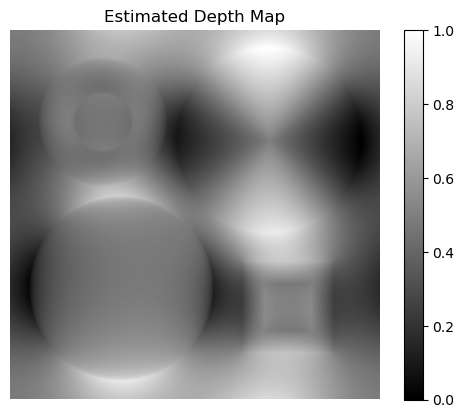

In [ ]:
nx, ny, nz = normals[..., 0], normals[..., 1], normals[..., 2] + 1e-8
p = -nx / nz  # dz/dx
q = -ny / nz  # dz/dy

def poisson_solver(p, q):
    H, W = p.shape
    f = np.zeros((H, W), dtype=np.float32)
    f[:, 1:] += p[:, 1:] - p[:, :-1]
    f[1:, :] += q[1:, :] - q[:-1, :]

    Fy = np.fft.fft2(f)
    y, x = np.meshgrid(np.arange(H), np.arange(W), indexing='ij')
    denom = (2 * np.cos(2 * np.pi * x / W) - 2) + (2 * np.cos(2 * np.pi * y / H) - 2)
    denom[0, 0] = 1
    Fz = Fy / denom
    Fz[0, 0] = 0
    z = np.fft.ifft2(Fz).real
    return z

depth = poisson_solver(p, q)
depth_vis = (depth - np.min(depth)) / (np.max(depth) - np.min(depth))
plt.imshow(depth_vis, cmap="gray")
plt.title('Estimated Depth Map')
plt.axis('off')
plt.colorbar()
plt.show()